# Linear algebra in python

In [1]:
import numpy as np


### Coefficient of matrix A

In [2]:
A = np.array([[2,3],[5,4]])
A

array([[2, 3],
       [5, 4]])

### Constant matrix B

In [3]:
B = np.array([8,20])
B

array([ 8, 20])

2X + 3Y = 8

5X+ 7Y = 20

### Solve for x

In [4]:
X = np.linalg.solve(A,B) # solve for X in AX = B
X

array([4., 0.])

---

# SVD in python

In [5]:
# generate a martrix of random numbers 4x3
A = np.random.rand(4,3)
A

array([[0.41701503, 0.48090596, 0.0577213 ],
       [0.57556325, 0.4156187 , 0.48348726],
       [0.44764647, 0.07030844, 0.1560701 ],
       [0.98074471, 0.43642208, 0.74487876]])

In [6]:
# Lets apply SVD to A
U, s, Vt = np.linalg.svd(A) # singular value decomposition
# print each matrix separately
print("U Matrix:", U)
print("----------------")
print("s Matrix:", s)
print("----------------")
print("Vt Matrix:", Vt)


U Matrix: [[-0.31885633  0.91522317 -0.16106467  0.1864279 ]
 [-0.49984917  0.05763505  0.50696096 -0.69987112]
 [-0.26129674 -0.15058788 -0.84641527 -0.43889463]
 [-0.76171219 -0.36928044  0.02509875  0.53178619]]
----------------
s Matrix: [1.70616962 0.36489896 0.19740055]
----------------
Vt Matrix: [[-0.7529594  -0.41724219 -0.5088822 ]
 [-0.04040992  0.80115533 -0.5970906 ]
 [-0.65682508  0.42902109  0.62009815]]


In [7]:
# check shape
print("U shape:", U.shape)
print("s shape:", s.shape)
print("Vt shape:", Vt.shape)

U shape: (4, 4)
s shape: (3,)
Vt shape: (3, 3)


-------------------

# Vectors in python

In [8]:
import numpy as np
import matplotlib.pyplot as plt

In [9]:
# create a vector
v = np.array([2,3]) # 2 = x, 3 = y
v

array([2, 3])

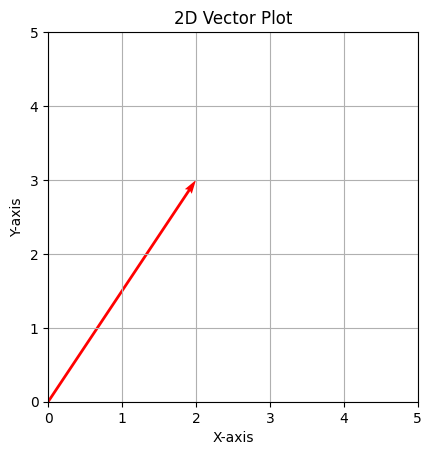

In [10]:
# Plot the vector
plt.figure()
plt.quiver(0, 0, v[0], v[1], angles='xy', scale_units='xy', scale=1, color='r')
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.grid()
plt.title("2D Vector Plot")
plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.gca().set_aspect('equal', adjustable='box')
plt.show()



----------

# Linear transformation

In [18]:
# Define the rotation matrix for 45 degree rotation 
theta = np.radians(45) # converting 45 degree to radians
rotation_matrix = np.array([[np.cos(theta), -np.sin(theta)],
                            [np.cos(theta), np.cos(theta)]])
print(rotation_matrix) 
print("----------------------------")   
print (v)                        

# Applying the transformation
v_transformed = np.dot(rotation_matrix, v)   
v_transformed                 





[[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]
----------------------------
[2 3]


array([-0.70710678,  3.53553391])

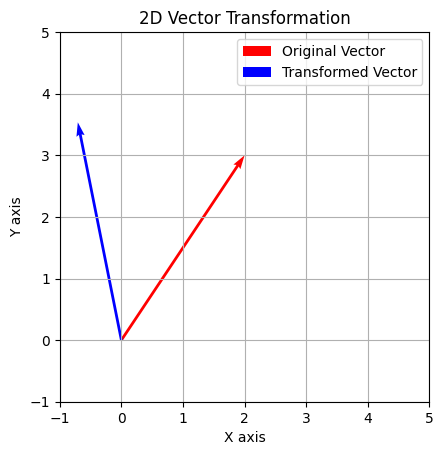

In [20]:
# Plotting the original and transformed vectors
plt.figure()
plt.quiver(0, 0, v[0], v[1], angles='xy', scale_units='xy', scale=1, color='r', label='Original Vector')
plt.quiver(0, 0, v_transformed[0], v_transformed[1], angles='xy', scale_units='xy', scale=1, color='b', label='Transformed Vector')
plt.xlim(-1, 5)
plt.ylim(-1, 5)
plt.grid()
plt.title('2D Vector Transformation')
plt.xlabel('X axis')
plt.ylabel('Y axis')
plt.legend()
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

----------------

# shear transformation

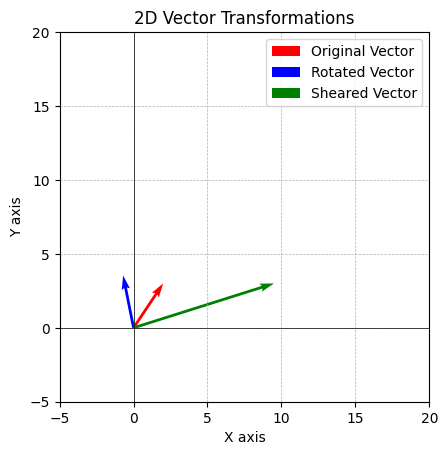

In [ ]:
shear_factor = 2.5
shear_matrix = np.array([[1, shear_factor], [0, 1]])

# Applying the shear transformation
v_sheared = np.dot(shear_matrix, v)

# Plotting the original, rotated, and sheared vectors
plt.figure()
plt.quiver(0, 0, v[0], v[1], angles='xy', scale_units='xy', scale=1, color='r', label='Original Vector')
plt.quiver(0, 0, v_transformed[0], v_transformed[1], angles='xy', scale_units='xy', scale=1, color='b', label='Rotated Vector')
plt.quiver(0, 0, v_sheared[0], v_sheared[1], angles='xy', scale_units='xy', scale=1, color='g', label='Sheared Vector')
plt.xlim(-5, 20)
plt.ylim(-5, 20)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.axhline(y=0, color='k',linewidth=0.5)
plt.axvline(x=0, color='k',linewidth=0.5)
plt.title('2D Vector Transformations')
plt.xlabel('X axis')
plt.ylabel('Y axis')
plt.legend()
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

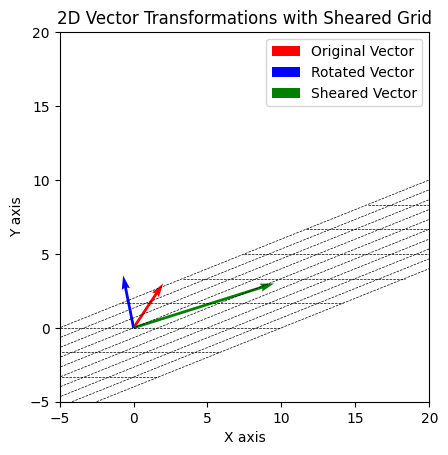

In [22]:

# Adjusting the plot to include the effect of shearing on the grid lines
# Creating a grid of points
x = np.linspace(-5, 10, 10)
y = np.linspace(-5, 10, 10)
X, Y = np.meshgrid(x, y)

# Applying shear transformation to the grid points
X_sheared, Y_sheared = np.dot(shear_matrix, [X.ravel(), Y.ravel()])
X_sheared = X_sheared.reshape(X.shape)
Y_sheared = Y_sheared.reshape(Y.shape)

# Plotting the sheared grid lines
plt.figure()
plt.quiver(0, 0, v[0], v[1], angles='xy', scale_units='xy', scale=1, color='r', label='Original Vector')
plt.quiver(0, 0, v_transformed[0], v_transformed[1], angles='xy', scale_units='xy', scale=1, color='b', label='Rotated Vector')
plt.quiver(0, 0, v_sheared[0], v_sheared[1], angles='xy', scale_units='xy', scale=1, color='g', label='Sheared Vector')

for i in range(len(x)):
    plt.plot(X_sheared[i, :], Y_sheared[i, :], 'k--', linewidth=0.5)
    plt.plot(X_sheared[:, i], Y_sheared[:, i], 'k--', linewidth=0.5)

plt.xlim(-5, 20)
plt.ylim(-5, 20)
plt.title('2D Vector Transformations with Sheared Grid')
plt.xlabel('X axis')
plt.ylabel('Y axis')
plt.legend()
plt.gca().set_aspect('equal', adjustable='box')
plt.show()